# Analysis of TEcount output (DESeq2)

# Imports

In [14]:
version

               _                           
platform       aarch64-apple-darwin20      
arch           aarch64                     
os             darwin20                    
system         aarch64, darwin20           
status                                     
major          4                           
minor          5.0                         
year           2025                        
month          04                          
day            11                          
svn rev        88135                       
language       R                           
version.string R version 4.5.0 (2025-04-11)
nickname       How About a Twenty-Six      

In [15]:
renv::init()
renv::activate()
renv::status()

A large number of files (8061 in total) have been discovered.
It may take renv a long time to scan these files for dependencies.
Consider using .renvignore to ignore irrelevant files.
See `?renv::dependencies` for more information.
Set `options(renv.config.dependencies.limit = Inf)` to disable this warning.


# BaparLab_Sequencing/snATACseq/ArchR/ArchRLogs ------------------------------
Error: directory contains 1069 files; consider ignoring this directory

Please see `?renv::dependencies` for more information.

- The project is out-of-sync -- use `renv::status()` for details.
This project does not contain a lockfile.
Use `renv::snapshot()` to create a lockfile.


In [16]:
library(DESeq2)
library(dplyr)
library(tidyr)
library(ggplot2)
library(pheatmap)
library(RColorBrewer)
library(clusterProfiler)
library(org.Mm.eg.db)
library(enrichplot)
library(DOSE)
library(biomaRt)
library(svglite)

## Define paths

In [ ]:
COUNT_DIR <- "TECounts/TEcounts_output" # where the cnt files are stored
METADATA_FILE <- "sample_metadata.csv" # where the sample_metadata.csv is stored

# Annotation, Filtering & Count Matrix

## Functions to create count matrix and annotate genes using Ensembl
- l1-5 was filtered out due to low quality
- RNA categories were determined based on the ID patterns

In [17]:
create_count_matrix <- function(count_dir = "RNAseq_output") {
  # List all count table files
  count_files <- list.files(count_dir, pattern = "*.cntTable", full.names = TRUE)
  
  # Filter out low quality samples (l1-5)
  count_files <- count_files[!grepl("l1-5", basename(count_files))]
  
  cat("Found", length(count_files), "count files\n")
  
  # Read and combine all count tables
  count_list <- lapply(count_files, function(file) {
    counts <- read.table(file, header = TRUE, sep = "\t")
    colnames(counts) <- c("gene_id", "counts")
    
    # Clean gene IDs
    counts$gene_id <- gsub('"', '', counts$gene_id)
    
    # Extract sample name
    sample_name <- gsub(".cntTable", "", basename(file))
    
    # Return with sample name
    colnames(counts)[2] <- sample_name
    return(counts)
  })
  
  # Merge all samples
  count_matrix <- Reduce(function(x, y) {
    merge(x, y, by = "gene_id", all = TRUE)
  }, count_list)
  
  # Replace NA with 0
  count_matrix[is.na(count_matrix)] <- 0
  
  # Convert to data frame and set gene_id as rownames
  count_matrix <- as.data.frame(count_matrix)
  rownames(count_matrix) <- count_matrix$gene_id
  count_matrix$gene_id <- NULL
  
  # Convert to numeric matrix for DESeq2
  count_matrix <- as.matrix(count_matrix)
  
  cat("Count matrix dimensions:", dim(count_matrix), "\n")
  cat("Sample names:", colnames(count_matrix), "\n")
  
  return(count_matrix)
}

# Function to annotate and categorize gene IDs
annotate_gene_ids <- function(gene_ids) {
  # Create annotation data frame
  annotations <- data.frame(
    gene_id = gene_ids,
    gene_id_clean = gsub("\\.[0-9]+$", "", gene_ids),  # Remove version numbers
    category = "unknown",
    element_type = "unknown",
    family = "unknown",
    stringsAsFactors = FALSE
  )
  
  # Categorize based on ID patterns
  annotations$category <- case_when(
    # Standard Ensembl genes
    grepl("^ENSMUSG", annotations$gene_id_clean) ~ "protein_coding",
    
    # RNA elements
    grepl(":RNA:", annotations$gene_id) ~ "rna_element",
    grepl("^7SK", annotations$gene_id) ~ "rna_element",
    
    # SINE elements
    grepl(":SINE", annotations$gene_id) ~ "sine_element",
    grepl(":Alu", annotations$gene_id) ~ "sine_element",
    grepl("^B[0-9]", annotations$gene_id) ~ "sine_element",
    
    # LINE elements
    grepl(":LINE", annotations$gene_id) ~ "line_element",
    grepl("^L1", annotations$gene_id) ~ "line_element",
    
    # LTR/Retroviral elements
    grepl(":LTR:", annotations$gene_id) ~ "ltr_element",
    grepl(":ERV", annotations$gene_id) ~ "ltr_element",
    grepl("^BGLII", annotations$gene_id) ~ "ltr_element",
    
    # DNA transposons
    grepl(":hAT", annotations$gene_id) ~ "dna_transposon",
    grepl("^Charlie", annotations$gene_id) ~ "dna_transposon",
    grepl("^Arthur", annotations$gene_id) ~ "dna_transposon",
    grepl("^BLACKJACK", annotations$gene_id) ~ "dna_transposon",
    
    # Other repetitive elements
    grepl(":CR1", annotations$gene_id) ~ "other_repetitive",
    grepl("^CR1_", annotations$gene_id) ~ "other_repetitive",
    grepl("^CYRA", annotations$gene_id) ~ "other_repetitive",
    
    TRUE ~ "other"
  )
  
  # Extract element family information
  annotations$family <- case_when(
    grepl("^B[0-9]", annotations$gene_id) ~ "B-family_SINE",
    grepl("^Charlie", annotations$gene_id) ~ "Charlie_hAT",
    grepl("^Arthur", annotations$gene_id) ~ "Arthur_hAT",
    grepl("^L1", annotations$gene_id) ~ "L1_LINE",
    grepl("^BGLII", annotations$gene_id) ~ "BGLII_ERV",
    grepl("^7SK", annotations$gene_id) ~ "7SK_RNA",
    TRUE ~ "other"
  )
  
  # Extract element type
  annotations$element_type <- case_when(
    annotations$category == "protein_coding" ~ "gene",
    annotations$category == "rna_element" ~ "rna",
    annotations$category == "sine_element" ~ "sine",
    annotations$category == "line_element" ~ "line",
    annotations$category == "ltr_element" ~ "ltr",
    annotations$category == "dna_transposon" ~ "dna_transposon",
    annotations$category == "other_repetitive" ~ "repetitive",
    TRUE ~ "other"
  )
  
  return(annotations)
}

# Function to get gene names and descriptions from Ensembl
get_gene_names <- function(ensembl_ids, cache_file = "RNAseq_results/gene_annotations_cache.rds") {
  # Clean Ensembl IDs (remove version numbers)
  clean_ids <- gsub("\\.[0-9]+$", "", ensembl_ids)
  
  # Get unique IDs
  unique_ids <- unique(clean_ids)
  
  cat("Fetching gene names for", length(unique_ids), "unique Ensembl IDs...\n")
  
  # Check if cache file exists
  if (file.exists(cache_file)) {
    cat("Loading gene annotations from cache file:", cache_file, "\n")
    cached_data <- readRDS(cache_file)
    cat("Loaded", nrow(cached_data), "gene annotations from cache\n")
    return(cached_data)
  }
  
  # List of Ensembl mirrors to try
  ensembl_hosts <- c(
    "https://www.ensembl.org",
    "https://useast.ensembl.org",
    "https://uswest.ensembl.org",
    "https://asia.ensembl.org"
  )
  
  gene_info <- NULL
  
  for (host in ensembl_hosts) {
    cat("Trying Ensembl host:", host, "\n")
    
    tryCatch({
      # Connect to Ensembl mouse database
      mart <- useMart("ensembl", dataset = "mmusculus_gene_ensembl", host = host)
      
      # Get gene information
      gene_info <- getBM(
        attributes = c("ensembl_gene_id", "external_gene_name", "gene_biotype", "description"),
        filters = "ensembl_gene_id",
        values = unique_ids,
        mart = mart
      )
      
      if (!is.null(gene_info) && nrow(gene_info) > 0) {
        cat("Successfully retrieved information for", nrow(gene_info), "genes from", host, "\n")
        
        # Save to cache
        saveRDS(gene_info, cache_file)
        cat("Saved gene annotations to cache:", cache_file, "\n")
        
        return(gene_info)
      }
      
    }, error = function(e) {
      cat("Error with host", host, ":", e$message, "\n")
    })
  }
  
  # If all hosts failed, create empty data frame with correct structure
  if (is.null(gene_info)) {
    cat("WARNING: All Ensembl hosts failed. Creating empty annotation data frame.\n")
    cat("Analysis will continue but gene names will not be available.\n")
    
    gene_info <- data.frame(
      ensembl_gene_id = character(0),
      external_gene_name = character(0),
      gene_biotype = character(0),
      description = character(0),
      stringsAsFactors = FALSE
    )
  }
  
  return(gene_info)
}

# Function to filter genes (remove low counts)
filter_low_counts <- function(count_matrix, min_count = 10, min_samples = 2) {
  # Keep genes with at least min_count reads in at least min_samples
  keep <- rowSums(count_matrix >= min_count) >= min_samples
  filtered_matrix <- count_matrix[keep, ]
  
  cat("Original genes:", nrow(count_matrix), "\n")
  cat("Genes after filtering:", nrow(filtered_matrix), "\n")
  
  return(filtered_matrix)
}

Create output directory

In [18]:
dir.create("RNAseq_results", showWarnings = FALSE)

Run functions

In [ ]:
# 1. Create count matrix
cat("Creating count matrix...\n")
count_matrix <- create_count_matrix(count_dir = COUNT_DIR)

# 2. Import sample metadata
cat("Importing sample metadata...\n")
metadata <- read.csv(METADATA_FILE)

# 3. Fix sample names in metadata (convert dots to hyphens)
metadata$sample_id_fixed <- gsub("\\.", "-", metadata$sample_id)
rownames(metadata) <- metadata$sample_id_fixed
metadata$group <- factor(metadata$group)

# 4. Remove l1-5 sample from metadata (was filtered out of count matrix)
metadata <- metadata[metadata$sample_id_fixed != "l1-5", ]

# 5. Annotate gene IDs
cat("Annotating gene IDs...\n")
annotations <- annotate_gene_ids(rownames(count_matrix))

# 6. Get gene names for protein coding genes
protein_coding_ids <- annotations$gene_id_clean[annotations$category == "protein_coding"]
gene_names <- get_gene_names(protein_coding_ids)

# 7. Add gene names to annotations
annotations <- annotations %>%
left_join(gene_names, by = c("gene_id_clean" = "ensembl_gene_id"))

# 8. Create annotated count matrix
count_matrix_annotated <- as.data.frame(count_matrix)
count_matrix_annotated$gene_id <- rownames(count_matrix_annotated)
count_matrix_annotated$gene_id_clean <- annotations$gene_id_clean
count_matrix_annotated$external_gene_name <- annotations$external_gene_name
count_matrix_annotated$category <- annotations$category
count_matrix_annotated$element_type <- annotations$element_type
count_matrix_annotated$family <- annotations$family
count_matrix_annotated$gene_biotype <- annotations$gene_biotype
count_matrix_annotated$description <- annotations$description

# 9. Save annotated count matrix
write.csv(count_matrix_annotated, "RNAseq/count_matrix_annotated.csv", row.names = FALSE)

# 10. Filter low counts
cat("Filtering low count genes...\n")
filtered_matrix <- filter_low_counts(count_matrix)

Creating count matrix...
Found 29 count files
Count matrix dimensions: 57458 29 
Sample names: h1-1 h1-2 h1-3 h1-4 h1-5 h2-1 h2-2 h2-3 h2-4 h2-5 h3-1 h3-2 h3-3 h3-4 h3-5 l1-1 l1-2 l1-3 l1-4 l2-1 l2-2 l2-3 l2-4 l2-5 l3-1 l3-2 l3-3 l3-4 l3-5 
Importing sample metadata...
Annotating gene IDs...
Fetching gene names for 56312 unique Ensembl IDs...
Trying Ensembl host: https://www.ensembl.org 
Successfully retrieved information for 51535 genes from https://www.ensembl.org 


Warning message in gzfile(file, mode):
“cannot open compressed file 'RNAseq_results/gene_annotations_cache.rds', probable reason 'No such file or directory'”


Error with host https://www.ensembl.org : cannot open the connection 
Trying Ensembl host: https://useast.ensembl.org 
Successfully retrieved information for 51535 genes from https://useast.ensembl.org 


Warning message in gzfile(file, mode):
“cannot open compressed file 'RNAseq_results/gene_annotations_cache.rds', probable reason 'No such file or directory'”


Error with host https://useast.ensembl.org : cannot open the connection 
Trying Ensembl host: https://uswest.ensembl.org 
Error with host https://uswest.ensembl.org : Failed to perform HTTP request. 
Trying Ensembl host: https://asia.ensembl.org 
Successfully retrieved information for 51535 genes from https://asia.ensembl.org 


Warning message in gzfile(file, mode):
“cannot open compressed file 'RNAseq_results/gene_annotations_cache.rds', probable reason 'No such file or directory'”


Error with host https://asia.ensembl.org : cannot open the connection 
Filtering low count genes...
Original genes: 57458 
Genes after filtering: 29590 


# DESeq2 & plotting functions 

Prepare data for DESeq2

In [26]:
sample_cols <- colnames(filtered_matrix)
count_matrix_clean <- as.matrix(filtered_matrix)
rownames(count_matrix_clean) <- rownames(filtered_matrix)

Function to run DESeq & pairwise comparisons

In [ ]:
run_deseq2 <- function(count_matrix, metadata, design_formula = ~ group) {
  # Create DESeq2 dataset
  dds <- DESeqDataSetFromMatrix(
    countData = round(count_matrix),
    colData = metadata,
    design = design_formula
  )
  
  # Set reference level (adjust based on your groups)
  dds$group <- relevel(dds$group, ref =  "LFD_1")
  
  # Run DESeq2
  dds <- DESeq(dds)
  
  return(dds)
}

# Function to run DESeq2 on all pairwise comparisons
run_all_deseq2_comparisons <- function(dds, metadata, gene_annotations = NULL, alpha = 0.05, lfc_threshold = 0) {
  groups <- levels(metadata$group)
  n_groups <- length(groups)
  
  cat("Running DESeq2 on all pairwise comparisons...\n")
  cat("Groups:", paste(groups, collapse = ", "), "\n")
  
  all_results <- list()
  
  # Create all pairwise combinations
  for (i in 1:(n_groups-1)) {
    for (j in (i+1):n_groups) {
      group1 <- groups[i]
      group2 <- groups[j]
      
      cat("Comparing", group1, "vs", group2, "...\n")
      
      # Create contrast
      contrast <- c("group", group2, group1)
      
      # Get results with error handling
      tryCatch({
        res <- results(dds, 
                       contrast = contrast,
                       alpha = alpha,
                       lfcThreshold = lfc_threshold)
        
        # Check if results are valid
        if (is.null(res) || nrow(res) == 0) {
          cat("  No results obtained for this comparison\n")
          next
        }
        
        # Convert to data frame and add metadata
        res_df <- as.data.frame(res)
        res_df$gene_id <- rownames(res_df)
        res_df$comparison <- paste(group2, "vs", group1)
        res_df$group1 <- group1
        res_df$group2 <- group2
        
        # Handle NA values in padj and log2FoldChange
        res_df$padj[is.na(res_df$padj)] <- 1  # Set NA p-values to 1 (not significant)
        res_df$log2FoldChange[is.na(res_df$log2FoldChange)] <- 0  # Set NA fold changes to 0
        
        # Add significance column
        res_df$significant <- ifelse(res_df$padj < alpha & abs(res_df$log2FoldChange) > lfc_threshold, 
                                    "Yes", "No")
        
        # Add gene annotations if provided
        if (!is.null(gene_annotations)) {
          # Merge with gene annotations
          res_df <- res_df %>%
            left_join(gene_annotations[, c("gene_id", "external_gene_name", "category", "element_type", "family", "gene_biotype")], 
                     by = "gene_id")
          
          # Create a display name column (gene name if available, otherwise Ensembl ID)
          res_df$display_name <- ifelse(!is.na(res_df$external_gene_name) & res_df$external_gene_name != "", 
                                       res_df$external_gene_name, 
                                       res_df$gene_id)
        }
        
        # Order by adjusted p-value
        res_df <- res_df[order(res_df$padj), ]
        
        # Store results
        comparison_name <- paste(group2, "_vs_", group1, sep = "")
        all_results[[comparison_name]] <- res_df
        
        # Save individual comparison results with gene names
        filename <- paste0("RNAseq_results/DEG/", comparison_name, "_significant_degs.csv")
        write.csv(res_df, filename, row.names = FALSE)
        
        # Count significant genes properly
        sig_count <- sum(res_df$significant == "Yes", na.rm = TRUE)
        cat("  Significant genes:", sig_count, "\n")
        cat("  Total genes:", nrow(res_df), "\n")
        cat("  Upregulated:", sum(res_df$significant == "Yes" & res_df$log2FoldChange > 0, na.rm = TRUE), "\n")
        cat("  Downregulated:", sum(res_df$significant == "Yes" & res_df$log2FoldChange < 0, na.rm = TRUE), "\n")
        
      }, error = function(e) {
        cat("  Error in comparison:", e$message, "\n")
      })
    }
  }
  
  if (length(all_results) == 0) {
    cat("No valid results obtained from any comparison\n")
    return(NULL)
  }
  
  # Create summary table
  summary_table <- do.call(rbind, lapply(names(all_results), function(comp_name) {
    res <- all_results[[comp_name]]
    data.frame(
      Comparison = comp_name,
      Total_Genes = nrow(res),
      Significant_Genes = sum(res$significant == "Yes", na.rm = TRUE),
      Upregulated = sum(res$significant == "Yes" & res$log2FoldChange > 0, na.rm = TRUE),
      Downregulated = sum(res$significant == "Yes" & res$log2FoldChange < 0, na.rm = TRUE)
    )
  }))
  
  write.csv(summary_table, "RNAseq_results/deseq2_summary.csv", row.names = FALSE)
  
  return(all_results)

}

In [36]:
# Run DESeq2
cat("Running DESeq2...\n")
dds <- run_deseq2(count_matrix_clean, metadata)

# Run all pairwise comparisons
cat("Running all pairwise comparisons...\n")
all_results <- run_all_deseq2_comparisons(dds, metadata, gene_annotations = count_matrix_annotated)

Running DESeq2...


converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



Running all pairwise comparisons...
Running DESeq2 on all pairwise comparisons...
Groups: HFD_1, HFD_2, HFD_3, LFD_1, LFD_2, LFD_3 
Comparing HFD_1 vs HFD_2 ...
  Significant genes: 17955 
  Total genes: 29590 
  Upregulated: 8853 
  Downregulated: 9102 
Comparing HFD_1 vs HFD_3 ...
  Significant genes: 4099 
  Total genes: 29590 
  Upregulated: 1772 
  Downregulated: 2327 
Comparing HFD_1 vs LFD_1 ...
  Significant genes: 17 
  Total genes: 29590 
  Upregulated: 1 
  Downregulated: 16 
Comparing HFD_1 vs LFD_2 ...
  Significant genes: 18991 
  Total genes: 29590 
  Upregulated: 9408 
  Downregulated: 9583 
Comparing HFD_1 vs LFD_3 ...
  Significant genes: 3190 
  Total genes: 29590 
  Upregulated: 1362 
  Downregulated: 1828 
Comparing HFD_2 vs HFD_3 ...
  Significant genes: 18498 
  Total genes: 29590 
  Upregulated: 9299 
  Downregulated: 9199 
Comparing HFD_2 vs LFD_1 ...
  Significant genes: 17262 
  Total genes: 29590 
  Upregulated: 8518 
  Downregulated: 8744 
Comparing HFD_2 v

# Specific plots

Creating heatmap for genes of interest...
Available genes in dataset: 29590 
Found 29 out of 30 genes
Heatmap created successfully!
Genes found: 29 
Genes missing: Il21 


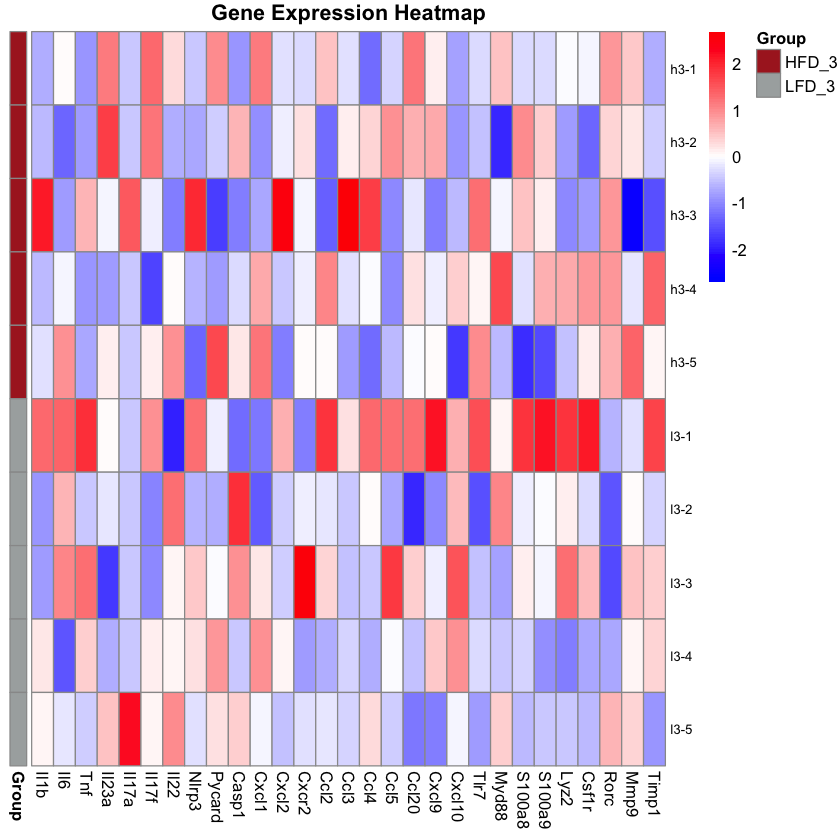

In [ ]:
create_gene_of_interest_heatmap <- function(dds, gene_list, gene_annotations = NULL, 
                                           sample_subset = NULL,
                                           title = "Gene Expression Heatmap", 
                                           filename = NULL) {
  
  vsd <- vst(dds, blind = FALSE)
  plot_data <- assay(vsd)
  
  if (!is.null(sample_subset)) {
    plot_data <- plot_data[, sample_subset]
  }
  
  cat("Available genes in dataset:", nrow(plot_data), "\n")
  
  found_genes <- c()
  gene_mapping <- c()
  
  for (gene in gene_list) {
    if (!is.null(gene_annotations)) {
      gene_match <- gene_annotations$gene_id[gene_annotations$external_gene_name == gene]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
      
      gene_match <- gene_annotations$gene_id[grepl(gene, gene_annotations$external_gene_name, ignore.case = TRUE)]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
    }
    
    if (grepl("^ENSMUSG", gene) && gene %in% rownames(plot_data)) {
      found_genes <- c(found_genes, gene)
      gene_mapping[gene] <- gene
    }
  }
  
  cat("Found", length(found_genes), "out of", length(gene_list), "genes\n")
  
  if (length(found_genes) == 0) {
    cat("No genes found in the dataset\n")
    return(NULL)
  }
  
  plot_data_subset <- plot_data[found_genes, ]
  rownames(plot_data_subset) <- gene_mapping[rownames(plot_data_subset)]
  
  # Transpose the data
  plot_data_transposed <- t(plot_data_subset)
  
  annotation_row <- data.frame(
    Group = colData(vsd)[rownames(plot_data_transposed), "group"],
    row.names = rownames(plot_data_transposed)
  )
  
  ann_colors <- list(
    Group = c("HFD_3" = "#ab2426", "LFD_3" = "#a9aeae")
  )
  
  p <- pheatmap(plot_data_transposed,
                 annotation_row = annotation_row,
                 annotation_colors = ann_colors,
                 scale = "column",
                 show_rownames = TRUE,
                 show_colnames = TRUE,
                 main = title,
                 fontsize_row = 8,
                 fontsize_col = 10,
                 fontface_col = "italic",
                 cluster_rows = FALSE,
                 cluster_cols = FALSE,
                 color = colorRampPalette(c("blue", "white", "red"))(100))
  
  if (!is.null(filename)) {
    ggsave(filename, p, width = 10, height = 6, dpi = 300)
  }
  
  return(list(
    plot = p,
    found_genes = found_genes,
    gene_mapping = gene_mapping,
    plot_data = plot_data_transposed
  ))
}

genes_of_interest <- c("Il1b", "Il6", "Tnf", "Il23a", "Il17a", "Il17f", "Il22", 
                       "Nlrp3", "Pycard", "Casp1", "Cxcl1", "Cxcl2", "Cxcr2", 
                       "Ccl2", "Ccl3", "Ccl4", "Ccl5", "Ccl20", "Cxcl9", "Cxcl10", 
                       "Tlr7", "Myd88", "S100a8", "S100a9", "Lyz2", "Csf1r", 
                       "Rorc", "Il21", "Mmp9", "Timp1")

samples_to_include <- colnames(results$dds)[colData(results$dds)$group %in% c("HFD_3", "LFD_3")]

cat("Creating heatmap for genes of interest...\n")
immune_heatmap <- create_gene_of_interest_heatmap(
  dds = results$dds,
  gene_list = genes_of_interest,
  gene_annotations = results$count_matrix_annotated,
  sample_subset = samples_to_include,
#   title = "Immune Response Genes Expression (HFD_3 vs LFD_3)",
  filename = "RNAseq_results/immune_genes_heatmap_HFD3_LFD3.svg"
)

if (!is.null(immune_heatmap)) {
  cat("Heatmap created successfully!\n")
  cat("Genes found:", length(immune_heatmap$found_genes), "\n")
  cat("Genes missing:", setdiff(genes_of_interest, immune_heatmap$gene_mapping), "\n")
  
  write.csv(immune_heatmap$plot_data, "RNAseq_results/immune_genes_expression_data_HFD3_LFD3.csv")
}

Creating PCA plot for all samples (genes of interest only)...


Found 29 out of 30 genes for PCA
PCA plot saved to: RNAseq_results/pca_plot_all_samples_immune_genes.png 

Variance explained by PC1: 72.5 %
Variance explained by PC2: 9.5 %

Creating PCA plot for HFD_3 vs LFD_3 (genes of interest only)...
Found 29 out of 30 genes for PCA
PCA plot saved to: RNAseq_results/pca_plot_HFD3_LFD3_immune_genes.svg 


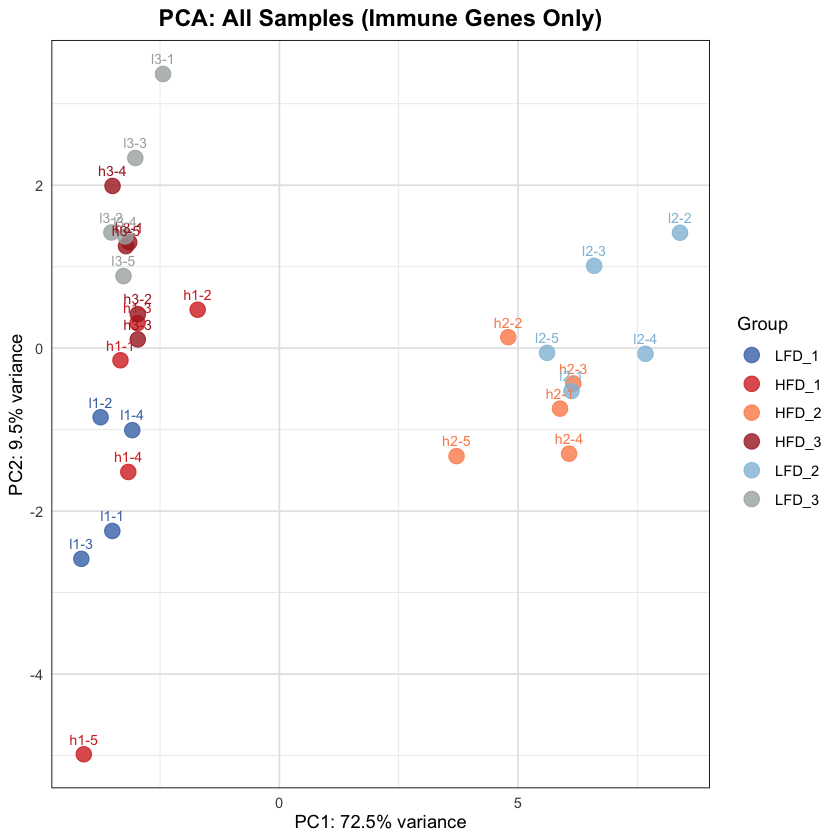


Variance explained by PC1: 30.7 %
Variance explained by PC2: 24.3 %


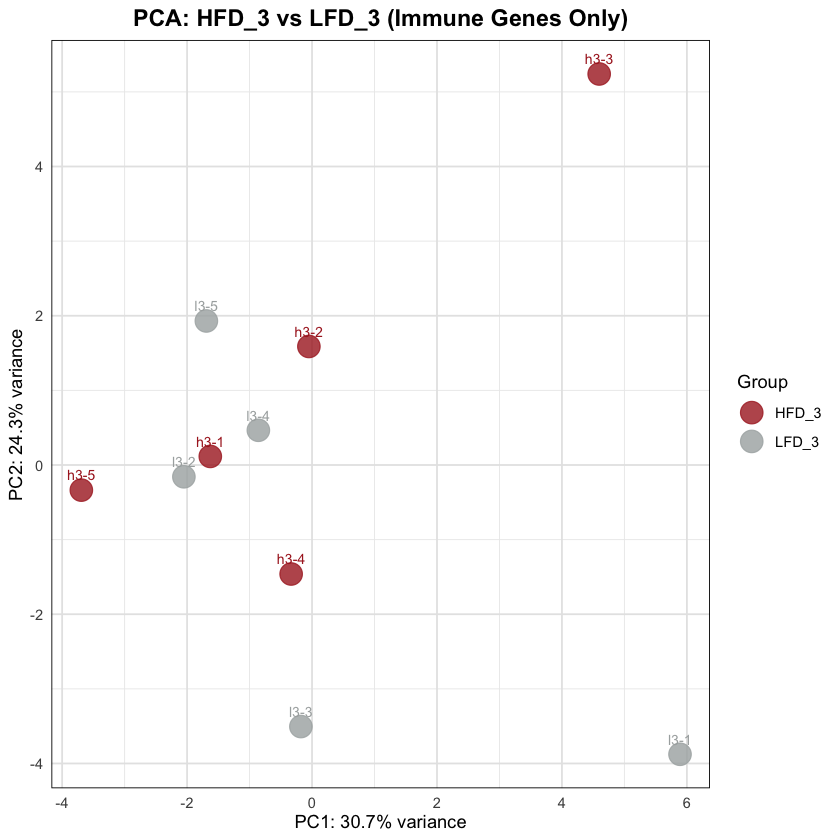

In [ ]:
create_pca_plot_genes_of_interest <- function(dds, gene_list, gene_annotations = NULL, 
                                               sample_subset = NULL, 
                                               title = "PCA Plot", filename = NULL,
                                               point_size = 4) {  
  
  # Get VST-transformed data
  vsd <- vst(dds, blind = FALSE)
  plot_data <- assay(vsd)
  
  # Subset to specific samples if provided
  if (!is.null(sample_subset)) {
    plot_data <- plot_data[, sample_subset]
    vsd_subset <- vsd[, sample_subset]
  } else {
    vsd_subset <- vsd
  }
  
  # Find genes of interest
  found_genes <- c()
  gene_mapping <- c()
  
  for (gene in gene_list) {
    if (!is.null(gene_annotations)) {
      gene_match <- gene_annotations$gene_id[gene_annotations$external_gene_name == gene]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
      
      gene_match <- gene_annotations$gene_id[grepl(gene, gene_annotations$external_gene_name, ignore.case = TRUE)]
      if (length(gene_match) > 0 && gene_match[1] %in% rownames(plot_data)) {
        found_genes <- c(found_genes, gene_match[1])
        gene_mapping[gene_match[1]] <- gene
        next
      }
    }
  }
  
  cat("Found", length(found_genes), "out of", length(gene_list), "genes for PCA\n")
  
  if (length(found_genes) == 0) {
    cat("No genes found in the dataset\n")
    return(NULL)
  }
  
  # Subset to genes of interest
  plot_data_subset <- plot_data[found_genes, ]
  
  # Perform PCA manually
  pca_result <- prcomp(t(plot_data_subset), scale. = TRUE, center = TRUE)
  
  # Calculate variance explained
  percent_var <- round(100 * pca_result$sdev^2 / sum(pca_result$sdev^2), 1)
  
  # Create data frame for plotting
  pca_data <- data.frame(
    PC1 = pca_result$x[, 1],
    PC2 = pca_result$x[, 2],
    name = colnames(plot_data_subset),
    group = colData(vsd_subset)$group
  )
  
  # Create plot
  p <- ggplot(pca_data, aes(x = PC1, y = PC2, color = group, label = name)) +
    geom_point(size = point_size, alpha = 0.8) + 
    geom_text(vjust = -1, hjust = 0.5, size = 3, show.legend = FALSE) +
    scale_color_manual(values = c(
      "HFD_1" = "#d73027", 
      "HFD_2" = "#fc8d59", 
      "HFD_3" = "#ab2426",
      "LFD_1" = "#4575b4", 
      "LFD_2" = "#91bfdb", 
      "LFD_3" = "#a9aeae"
    )) +
    labs(
      title = title,
      x = paste0("PC1: ", percent_var[1], "% variance"),
      y = paste0("PC2: ", percent_var[2], "% variance"),
      color = "Group"
    ) +
    theme_minimal() +
    theme(
      plot.title = element_text(hjust = 0.5, size = 14, face = "bold"),
      legend.position = "right",
      panel.grid.major = element_line(color = "gray90"),
      panel.border = element_rect(color = "black", fill = NA, size = 0.5)
    )
  
  if (!is.null(filename)) {
    ggsave(filename, p, width = 10, height = 8, dpi = 300)
    cat("PCA plot saved to:", filename, "\n")
  }
  
  return(list(
    plot = p,
    pca_data = pca_data,
    pca_result = pca_result,
    percent_var = percent_var,
    genes_used = found_genes
  ))
}

genes_of_interest <- c("Il1b", "Il6", "Tnf", "Il23a", "Il17a", "Il17f", "Il22", 
                       "Nlrp3", "Pycard", "Casp1", "Cxcl1", "Cxcl2", "Cxcr2", 
                       "Ccl2", "Ccl3", "Ccl4", "Ccl5", "Ccl20", "Cxcl9", "Cxcl10", 
                       "Tlr7", "Myd88", "S100a8", "S100a9", "Lyz2", "Csf1r", 
                       "Rorc", "Il21", "Mmp9", "Timp1")

# PCA with HFD_3 and LFD_3 only, genes of interest only
samples_to_include <- colnames(results$dds)[colData(results$dds)$group %in% c("HFD_3", "LFD_3")]

cat("Creating PCA plot for HFD_3 vs LFD_3 (genes of interest only)...\n")
pca_genes_hfd3_lfd3 <- create_pca_plot_genes_of_interest(
  dds = results$dds,
  gene_list = genes_of_interest,
  gene_annotations = results$count_matrix_annotated,
  sample_subset = samples_to_include,
  title = "PCA: HFD_3 vs LFD_3 (Immune Genes Only)",
  filename = "RNAseq_results/pca_plot_HFD3_LFD3_immune_genes.svg",
  point_size = 6
)

print(pca_genes_hfd3_lfd3$plot)
cat("\nVariance explained by PC1:", pca_genes_hfd3_lfd3$percent_var[1], "%\n")
cat("Variance explained by PC2:", pca_genes_hfd3_lfd3$percent_var[2], "%\n")